# Kondo (2009) — Stripe Regeneration: "Wound Healing" Initial Condition

Demonstrates pattern formation from an initial condition of
**horizontal Turing stripes** with a rectangular section cleared
and replaced by randomly scattered pigment-cell dots — modelling
a wound-healing experiment on zebrafish skin.

```
┌────────────────────────┐
│  ═══ stripe ═══        │   ← existing Turing pattern
│  ─────────────────     │
│  ╔══ WOUND PATCH ══╗   │   ← cleared region + random dots
│  ║  · u ·  · v ·  ║   │
│  ╚═════════════════╝   │
│  ─────────────────     │
│  ═══ stripe ═══        │
└────────────────────────┘
```

**Three rows**

| Row | Parameters | Expected result |
|-----|-----------|-----------------|
| 1 | Wild type | Stripes regenerate — wound heals seamlessly |
| 2 | Leopard mutant | Spots form inside wound, then spread |
| 3 | Jaguar/Obelix | Wider stripes regenerate |

**Colour encoding**

| Colour | Field | Biology |
|--------|-------|---------|
| Yellow | high $u$ | melanophores |
| Blue | high $v$ | xanthophores |
| Black | both ≈ 0 | wound / empty region |

## Cell 1 — Imports and configuration

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
import time
import sys
import os
import warnings

sys.path.insert(0, os.path.abspath("."))

from kondo_rd import (
    WILDTYPE, LEOPARD, JAGUAR,
    laplacian_neumann,
    F_prod, G_prod, H_prod,
    dispersion_relation,
)

plt.rcParams.update({
    "figure.dpi"        : 130,
    "axes.titlesize"    : 12,
    "axes.labelsize"    : 11,
    "font.family"       : "sans-serif",
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
})

ALL_PARAMS = [WILDTYPE, LEOPARD, JAGUAR]
print("✓  Imports OK")
print(f"   Parameter sets: {[p['name'] for p in ALL_PARAMS]}")

✓  Imports OK
   Parameter sets: ['Wild Type', 'Leopard Mutant', 'Jaguar/Obelix Mutant']


## Cell 2 — Colour helpers

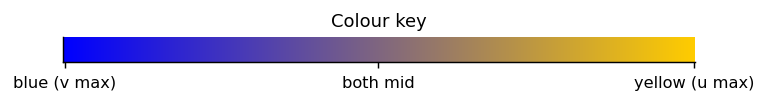

✓  Colour helpers defined


In [2]:
def make_rgb(u, v, u_scale, v_scale):
    """
    Yellow / blue RGB image.

    Channel mapping
    ---------------
    R = u_n,  G = 0.80 · u_n  →  yellow when u is high
    B = v_n                   →  blue   when v is high
    Both high → warm cyan  |  Both low → black

    Parameters
    ----------
    u, v     : (H, W) float arrays
    u_scale  : values ≥ u_scale render as fully yellow (clipped)
    v_scale  : values ≥ v_scale render as fully blue   (clipped)
    """
    u_n = np.clip(u / (u_scale + 1e-14), 0.0, 1.0).astype(np.float32)
    v_n = np.clip(v / (v_scale + 1e-14), 0.0, 1.0).astype(np.float32)
    rgb        = np.zeros(u.shape + (3,), dtype=np.float32)
    rgb[..., 0] = u_n
    rgb[..., 1] = u_n * 0.80
    rgb[..., 2] = v_n
    return rgb


def phys_scales(p):
    """Return (u_scale, v_scale) = (U/cu, V/cv)  — absolute physical maxima."""
    return p["U"] / p["cu"], p["V"] / p["cv"]


def final_scales(sim):
    """
    Return (u_scale, v_scale) from the 99th percentile of the *final* frame.

    This makes the final pattern fully saturated so that the early frames
    (which have lower amplitudes) are not over-exposed.  A safety floor of
    5 % of the physical maximum prevents division-by-zero on flat fields.
    """
    p    = sim["params"]
    u_sc = max(float(np.percentile(sim["final"]["u"], 99)),
               p["U"] / p["cu"] * 0.05)
    v_sc = max(float(np.percentile(sim["final"]["v"], 99)),
               p["V"] / p["cv"] * 0.05)
    return u_sc, v_sc


# ── quick colour-key display ──────────────────────────────────────────────────
_x  = np.linspace(0, 1, 256)
_ku = np.outer(np.ones(48), _x)
_kv = np.outer(np.ones(48), _x[::-1])
fig_key, ax_key = plt.subplots(figsize=(6, 0.9))
ax_key.imshow(make_rgb(_ku, _kv, 1.0, 1.0),
              origin="lower", aspect="auto", interpolation="bilinear")
ax_key.set_xticks([0, 127, 255])
ax_key.set_xticklabels(["blue (v max)", "both mid", "yellow (u max)"], fontsize=9)
ax_key.set_yticks([])
ax_key.set_title("Colour key", fontsize=10)
plt.tight_layout()
plt.show()
print("✓  Colour helpers defined")

## Cell 3 — Compute dominant Turing wavelength $\lambda^*$

$$\lambda^* = \frac{2\pi}{k^*}, \qquad
  k^* = \arg\!\max_{k>0}\; \sigma(k)$$

The stripe spacing is set to $\lambda^*$ so that the background stripes are
exactly the "natural" wavelength of each parameter set.

In [3]:
def compute_lambda_star(p, k_max=2.5, n_k=4000):
    """
    Compute the dominant Turing wavenumber and wavelength for parameter set p.

    Returns
    -------
    lam_star   : float   dominant wavelength  λ* = 2π/k*  [grid units]
    k_star     : float   dominant wavenumber  k*          [rad / grid-unit]
    sigma_star : float   peak dispersion-relation growth rate  σ*
    """
    k_arr, sig_arr = dispersion_relation(p, k_max=k_max, n_k=n_k)
    # consider only k > 0 to avoid the k=0 (homogeneous) mode
    with_k = k_arr > 1e-8
    if np.any(sig_arr[with_k] > 0):
        idx = int(np.argmax(np.where(with_k, sig_arr, -np.inf)))
    else:
        # no Turing instability — take the least-stable mode
        idx = int(np.argmax(np.where(with_k, sig_arr, -np.inf)))
    k_s   = float(k_arr[idx])
    lam_s = 2.0 * np.pi / k_s
    sig_s = float(sig_arr[idx])
    return lam_s, k_s, sig_s


# ── print λ* table ────────────────────────────────────────────────────────────
print(f"\n  {'Parameter set':<22}  {'k*':>8}  {'λ* (grid u.)':>14}  {'σ*':>12}")
print("  " + "─" * 60)

LAM_STAR = {}   # λ* keyed by param-set name  (used by IC function below)
K_STAR   = {}

for p in ALL_PARAMS:
    lam, k, sig = compute_lambda_star(p)
    LAM_STAR[p["name"]] = lam
    K_STAR[p["name"]]   = k
    n_stripes = 128.0 / lam
    print(f"  {p['name']:<22}  {k:>8.4f}  {lam:>14.2f}  {sig:>12.6f}"
          f"  ({n_stripes:.1f} stripes / 128 px)")


  Parameter set                 k*    λ* (grid u.)            σ*
  ────────────────────────────────────────────────────────────
  Wild Type                 0.5481           11.46      0.004556  (11.2 stripes / 128 px)
  Leopard Mutant            0.5481           11.46      0.004556  (11.2 stripes / 128 px)
  Jaguar/Obelix Mutant      0.3875           16.21      0.004556  (7.9 stripes / 128 px)


## Cell 4 — `stripes_with_dot_patch_ic`: the new initial condition

Build the IC in three steps:

1. **Stripe background** — horizontal bands, spacing $= \lambda^*$,
   alternating between full-amplitude $u$ (yellow) and $v$ (blue).
   Either *step* (binary) or *sinusoidal* profile.

2. **Clear the wound patch** — set $u = v = 0$ inside the rectangle.

3. **Seed random dots** — scatter $n_\text{dots}$ melanophore dots
   (amplitude $U/c_u$) and $n_\text{dots}$ xanthophore dots
   (amplitude $V/c_v$) at independent random positions inside the patch.

In [4]:
def stripes_with_dot_patch_ic(
    p,
    n             = 128,
    lam_override  = None,
    phase_offset  = 0.0,
    stripe_type   = "step",
    patch_bounds  = None,
    n_dots_each   = 30,
    dot_radius    = 2.5,
    seed          = 42,
):
    """
    Horizontal Turing-stripe background with a rectangular wound region
    cleared of stripes and seeded with random melanophore / xanthophore dots.

    Parameters
    ----------
    p             : parameter dict  (WILDTYPE / LEOPARD / JAGUAR)
    n             : grid size (n × n pixels)
    lam_override  : stripe wavelength in grid units
                    default: λ* from the dispersion relation
    phase_offset  : phase shift of the stripe pattern in radians
                    (0 → u-stripe begins at row 0)
    stripe_type   : ``"step"``  – binary full-amplitude stripes  [default]
                    ``"sine"``  – smooth sinusoidal profile (values in [0, max])
    patch_bounds  : (x0_frac, x1_frac, y0_frac, y1_frac)
                    corner fractions of n  (0 = left/bottom, 1 = right/top)
                    default: central square  (0.33, 0.67, 0.33, 0.67)
    n_dots_each   : number of u-dots *and* v-dots placed (independently)
    dot_radius    : disc radius for each dot, in pixels
    seed          : NumPy random-generator seed

    Returns
    -------
    u0, v0, w0 : (n, n) float64 arrays  (all ≥ 0)
    """
    # ── physical amplitude ceilings ───────────────────────────────────────────
    u_amp = p["U"] / p["cu"]
    v_amp = p["V"] / p["cv"]

    # ── 1. Dominant wavelength ────────────────────────────────────────────────
    if lam_override is not None:
        lam = float(lam_override)
    else:
        # Use pre-computed table if available, otherwise compute on the fly
        if p["name"] in LAM_STAR:
            lam = LAM_STAR[p["name"]]
        else:
            lam, _, _ = compute_lambda_star(p)

    # ── 2. Stripe background  ─────────────────────────────────────────────────
    y   = np.arange(n, dtype=float)
    phi = 2.0 * np.pi * y / lam + phase_offset   # phase at each row
    s   = np.sin(phi)

    if stripe_type == "step":
        # Hard binary bands: u where sin ≥ 0, v where sin < 0
        u_1d = np.where(s >= 0, u_amp, 0.0)
        v_1d = np.where(s <  0, v_amp, 0.0)
    elif stripe_type == "sine":
        # Smooth profile: each field oscillates from 0 to its amplitude
        u_1d = u_amp * 0.5 * (1.0 + s)
        v_1d = v_amp * 0.5 * (1.0 - s)
    else:
        raise ValueError(f"stripe_type must be 'step' or 'sine', got '{stripe_type}'")

    # Broadcast 1-D row-profile → 2-D field (constant along x-axis)
    u0 = np.tile(u_1d[:, np.newaxis], (1, n)).copy()
    v0 = np.tile(v_1d[:, np.newaxis], (1, n)).copy()
    w0 = np.zeros((n, n), dtype=float)

    # ── 3. Wound patch bounds ─────────────────────────────────────────────────
    if patch_bounds is None:
        x0f, x1f, y0f, y1f = 0.33, 0.67, 0.33, 0.67
    else:
        x0f, x1f, y0f, y1f = patch_bounds

    # Convert fractions → integer pixel indices
    px0 = int(round(x0f * (n - 1)))
    px1 = int(round(x1f * (n - 1)))
    py0 = int(round(y0f * (n - 1)))
    py1 = int(round(y1f * (n - 1)))

    # ── 4. Clear stripes inside the wound ────────────────────────────────────
    u0[py0 : py1 + 1, px0 : px1 + 1] = 0.0
    v0[py0 : py1 + 1, px0 : px1 + 1] = 0.0

    # ── 5. Scatter random dots inside the wound ───────────────────────────────
    rng    = np.random.default_rng(seed)
    margin = max(int(dot_radius) + 2, 1)   # keep dots away from patch boundary

    x_lo = px0 + margin;  x_hi = px1 - margin
    y_lo = py0 + margin;  y_hi = py1 - margin

    if x_hi <= x_lo or y_hi <= y_lo:
        warnings.warn(
            f"Wound patch (width={px1-px0}, height={py1-py0} px) is too "
            f"small for dots with margin={margin}.  Dots omitted.",
            RuntimeWarning,
            stacklevel=2,
        )
        return u0, v0, w0

    Y_g, X_g = np.ogrid[:n, :n]

    for _ in range(n_dots_each):
        # Melanophore dot  (u)
        xc = int(rng.integers(x_lo, x_hi + 1))
        yc = int(rng.integers(y_lo, y_hi + 1))
        u0[(X_g - xc) ** 2 + (Y_g - yc) ** 2 <= dot_radius ** 2] = u_amp

        # Xanthophore dot  (v)  — independent position
        xc = int(rng.integers(x_lo, x_hi + 1))
        yc = int(rng.integers(y_lo, y_hi + 1))
        v0[(X_g - xc) ** 2 + (Y_g - yc) ** 2 <= dot_radius ** 2] = v_amp

    return u0, v0, w0


print("✓  stripes_with_dot_patch_ic defined")

✓  stripes_with_dot_patch_ic defined


## Cell 5 — Preview: annotated initial conditions for all three parameter sets

The dashed white rectangle marks the wound patch boundary.
Stripe count differs across parameter sets because $\lambda^*$ differs.

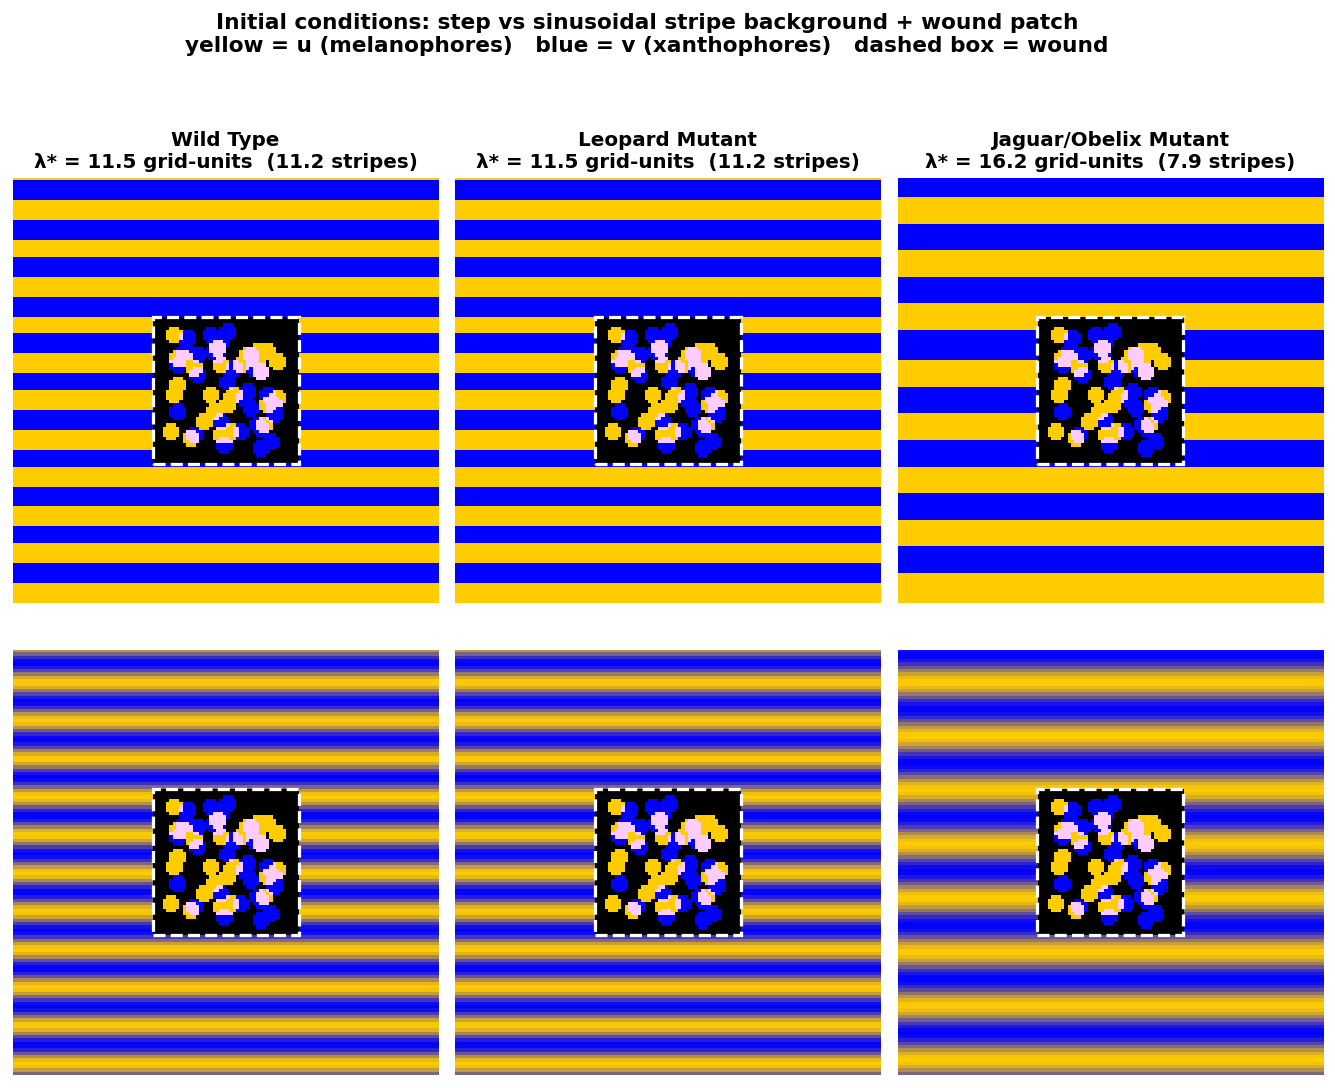

Saved  wound_ic_preview.png


In [5]:
PATCH = (0.33, 0.67, 0.33, 0.67)   # shared patch bounds  (x0f,x1f,y0f,y1f)
N     = 128                          # grid size

def add_patch_rect(ax, patch_bounds, n, lw=1.8,
                   ec="white", ls="--"):
    """Draw a dashed rectangle marking the wound patch."""
    px0 = int(round(patch_bounds[0] * (n - 1)))
    px1 = int(round(patch_bounds[1] * (n - 1)))
    py0 = int(round(patch_bounds[2] * (n - 1)))
    py1 = int(round(patch_bounds[3] * (n - 1)))
    ax.add_patch(Rectangle(
        (px0 - 0.5, py0 - 0.5),
        px1 - px0 + 1,
        py1 - py0 + 1,
        linewidth=lw, edgecolor=ec,
        facecolor="none", linestyle=ls,
    ))


fig_prev, axes_prev = plt.subplots(
    2, 3, figsize=(13, 9.0),
    gridspec_kw={"hspace": 0.10, "wspace": 0.04},
)

IC_CACHE = {}   # (u0, v0, w0) keyed by param-set name

for col_i, p in enumerate(ALL_PARAMS):
    lam = LAM_STAR[p["name"]]

    for row_i, stripe_type in enumerate(["step", "sine"]):
        u0, v0, w0 = stripes_with_dot_patch_ic(
            p, n=N,
            stripe_type  = stripe_type,
            patch_bounds = PATCH,
            n_dots_each  = 30,
            dot_radius   = 2.5,
            seed         = 42,
        )

        if stripe_type == "step":   # cache the step version for simulations
            IC_CACHE[p["name"]] = (u0, v0, w0)

        u_sc, v_sc = phys_scales(p)
        ax = axes_prev[row_i, col_i]
        ax.imshow(make_rgb(u0, v0, u_sc, v_sc),
                  origin="lower", aspect="equal", interpolation="nearest")
        add_patch_rect(ax, PATCH, N)
        ax.axis("off")

        if row_i == 0:
            ax.set_title(
                f"{p['name']}\n"
                f"λ* = {lam:.1f} grid-units  "
                f"({128/lam:.1f} stripes)",
                fontsize=11, fontweight="bold", pad=6,
            )
        if col_i == 0:
            ax.set_ylabel(
                f"stripe_type = '{stripe_type}'",
                fontsize=10, fontweight="bold",
                rotation=90, labelpad=8,
            )

fig_prev.suptitle(
    "Initial conditions: step vs sinusoidal stripe background + wound patch\n"
    "yellow = u (melanophores)   blue = v (xanthophores)   "
    "dashed box = wound",
    fontsize=12, fontweight="bold", y=1.02,
)
plt.savefig("wound_ic_preview.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  wound_ic_preview.png")

## Cell 6 — `simulate_ic`: forward-Euler PDE integrator

Defined locally so this notebook runs without `kondo_ic_patterns.py`.

In [6]:
def simulate_ic(
    p,
    u0, v0, w0,
    dt         = 0.5,
    n_steps    = 60_000,
    save_every = 20_000,
    verbose    = True,
):
    """
    Explicit-Euler integration of the Kondo (2009) RD system from a
    user-supplied initial condition on an n×n grid (Neumann BCs).

    Parameters
    ----------
    p          : parameter dict
    u0, v0, w0 : (n, n) initial fields  — any non-negative arrays
    dt         : time step  [must satisfy  dt ≤ 1 / (4·max(D))]
    n_steps    : total integration steps  (T_final = n_steps · dt)
    save_every : snapshot frequency in steps; t = 0 is always saved
    verbose    : print progress ticker

    Returns
    -------
    dict with keys
      ``'params'``     – parameter dict used
      ``'ic'``         – copy of the initial condition {u, v, w}
      ``'snapshots'``  – list of {step, time, u, v, w} dicts
      ``'final'``      – state at T_final (same format as snapshots)
    """
    n     = u0.shape[0]
    D_max = max(p["Du"], p["Dv"], p["Dw"])
    cfl   = 1.0 / (4.0 * D_max)
    if dt > cfl:
        raise ValueError(
            f"dt = {dt:.4f} exceeds the CFL stability limit "
            f"{cfl:.4f}  (D_max = {D_max}). "
            f"Please use  dt ≤ {cfl:.4f}."
        )

    if verbose:
        print(f"\n{'═' * 56}")
        print(f"  {p['name']}")
        print(f"  Grid {n}×{n}  |  dt = {dt}  |  "
              f"T_final = {n_steps * dt:.0f}  |  steps = {n_steps:,}")
        print(f"  Saves: t = 0  +  every {save_every} steps")
        print("  Integrating:  ", end="", flush=True)

    u, v, w = u0.copy(), v0.copy(), w0.copy()
    snaps   = [{"step": 0, "time": 0.0,
                "u": u.copy(), "v": v.copy(), "w": w.copy()}]
    dot_int = max(1, n_steps // 20)

    for step in range(1, n_steps + 1):
        Lu = laplacian_neumann(u)
        Lv = laplacian_neumann(v)
        Lw = laplacian_neumann(w)

        u += dt * (F_prod(v, w, p) - p["cu"] * u + p["Du"] * Lu)
        v += dt * (G_prod(u, w, p) - p["cv"] * v + p["Dv"] * Lv)
        w += dt * (H_prod(u, v, p) - p["cw"] * w + p["Dw"] * Lw)

        np.clip(u, 0.0, None, out=u)
        np.clip(v, 0.0, None, out=v)
        np.clip(w, 0.0, None, out=w)

        if step % save_every == 0:
            snaps.append({
                "step": step, "time": step * dt,
                "u": u.copy(), "v": v.copy(), "w": w.copy(),
            })
        if verbose and step % dot_int == 0:
            print("▪", end="", flush=True)

    final = {
        "step": n_steps, "time": n_steps * dt,
        "u": u.copy(), "v": v.copy(), "w": w.copy(),
    }
    if verbose:
        print(f"\n  Done.  "
              f"u ∈ [{u.min():.2f}, {u.max():.2f}]  "
              f"v ∈ [{v.min():.2f}, {v.max():.2f}]  "
              f"w ∈ [{w.min():.2f}, {w.max():.2f}]")

    return {
        "params"   : p,
        "ic"       : {"u": u0.copy(), "v": v0.copy(), "w": w0.copy()},
        "snapshots": snaps,
        "final"    : final,
    }


print("✓  simulate_ic defined")

✓  simulate_ic defined


## Cell 7 — Wild-type simulation

In [7]:
u0, v0, w0 = IC_CACHE[WILDTYPE["name"]]

t0     = time.time()
sim_wt = simulate_ic(
    WILDTYPE, u0, v0, w0,
    dt         = 0.5,
    n_steps    = 60_000,
    save_every = 20_000,
    verbose    = True,
)
print(f"  Wall time: {time.time() - t0:.1f} s")


════════════════════════════════════════════════════════
  Wild Type
  Grid 128×128  |  dt = 0.5  |  T_final = 30000  |  steps = 60,000
  Saves: t = 0  +  every 20000 steps
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.16, 6.15]  v ∈ [0.26, 9.26]  w ∈ [0.68, 4.40]
  Wall time: 39.3 s


## Cell 8 — Leopard mutant simulation

In [8]:
u0, v0, w0  = IC_CACHE[LEOPARD["name"]]

t0      = time.time()
sim_leo = simulate_ic(
    LEOPARD, u0, v0, w0,
    dt         = 0.5,
    n_steps    = 60_000,
    save_every = 20_000,
    verbose    = True,
)
print(f"  Wall time: {time.time() - t0:.1f} s")


════════════════════════════════════════════════════════
  Leopard Mutant
  Grid 128×128  |  dt = 0.5  |  T_final = 30000  |  steps = 60,000
  Saves: t = 0  +  every 20000 steps
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.29, 5.96]  v ∈ [0.08, 8.69]  w ∈ [1.44, 4.94]
  Wall time: 43.7 s


## Cell 9 — Jaguar / Obelix simulation

In [9]:
u0, v0, w0  = IC_CACHE[JAGUAR["name"]]

t0      = time.time()
sim_jag = simulate_ic(
    JAGUAR, u0, v0, w0,
    dt         = 0.5,
    n_steps    = 60_000,
    save_every = 20_000,
    verbose    = True,
)
print(f"  Wall time: {time.time() - t0:.1f} s")

ALL_SIMS   = [sim_wt, sim_leo, sim_jag]
ROW_LABELS = [
    "Wild type\n(stripe + wound IC)",
    "Leopard mutant\n(stripe + wound IC)",
    "Jaguar/Obelix\n(stripe + wound IC)",
]
print("\nAll simulations complete.")


════════════════════════════════════════════════════════
  Jaguar/Obelix Mutant
  Grid 128×128  |  dt = 0.5  |  T_final = 30000  |  steps = 60,000
  Saves: t = 0  +  every 20000 steps
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.19, 6.17]  v ∈ [0.28, 9.14]  w ∈ [0.77, 4.36]
  Wall time: 40.8 s

All simulations complete.


## Cell 10 — Main figure: wound-healing evolution

Four time panels per row mirroring the figure layout:
`Initial Pattern  ▷  [early]  ▷  [mid]  ▷  Stable Pattern`

The wound patch boundary is annotated with a dashed white rectangle
on the IC frame only.  Colour scale is fixed per row to the
99th-percentile of the **final** frame so that the initial near-zero
background appears black and the final pattern is fully saturated.

/tmp/ipykernel_553/132689845.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


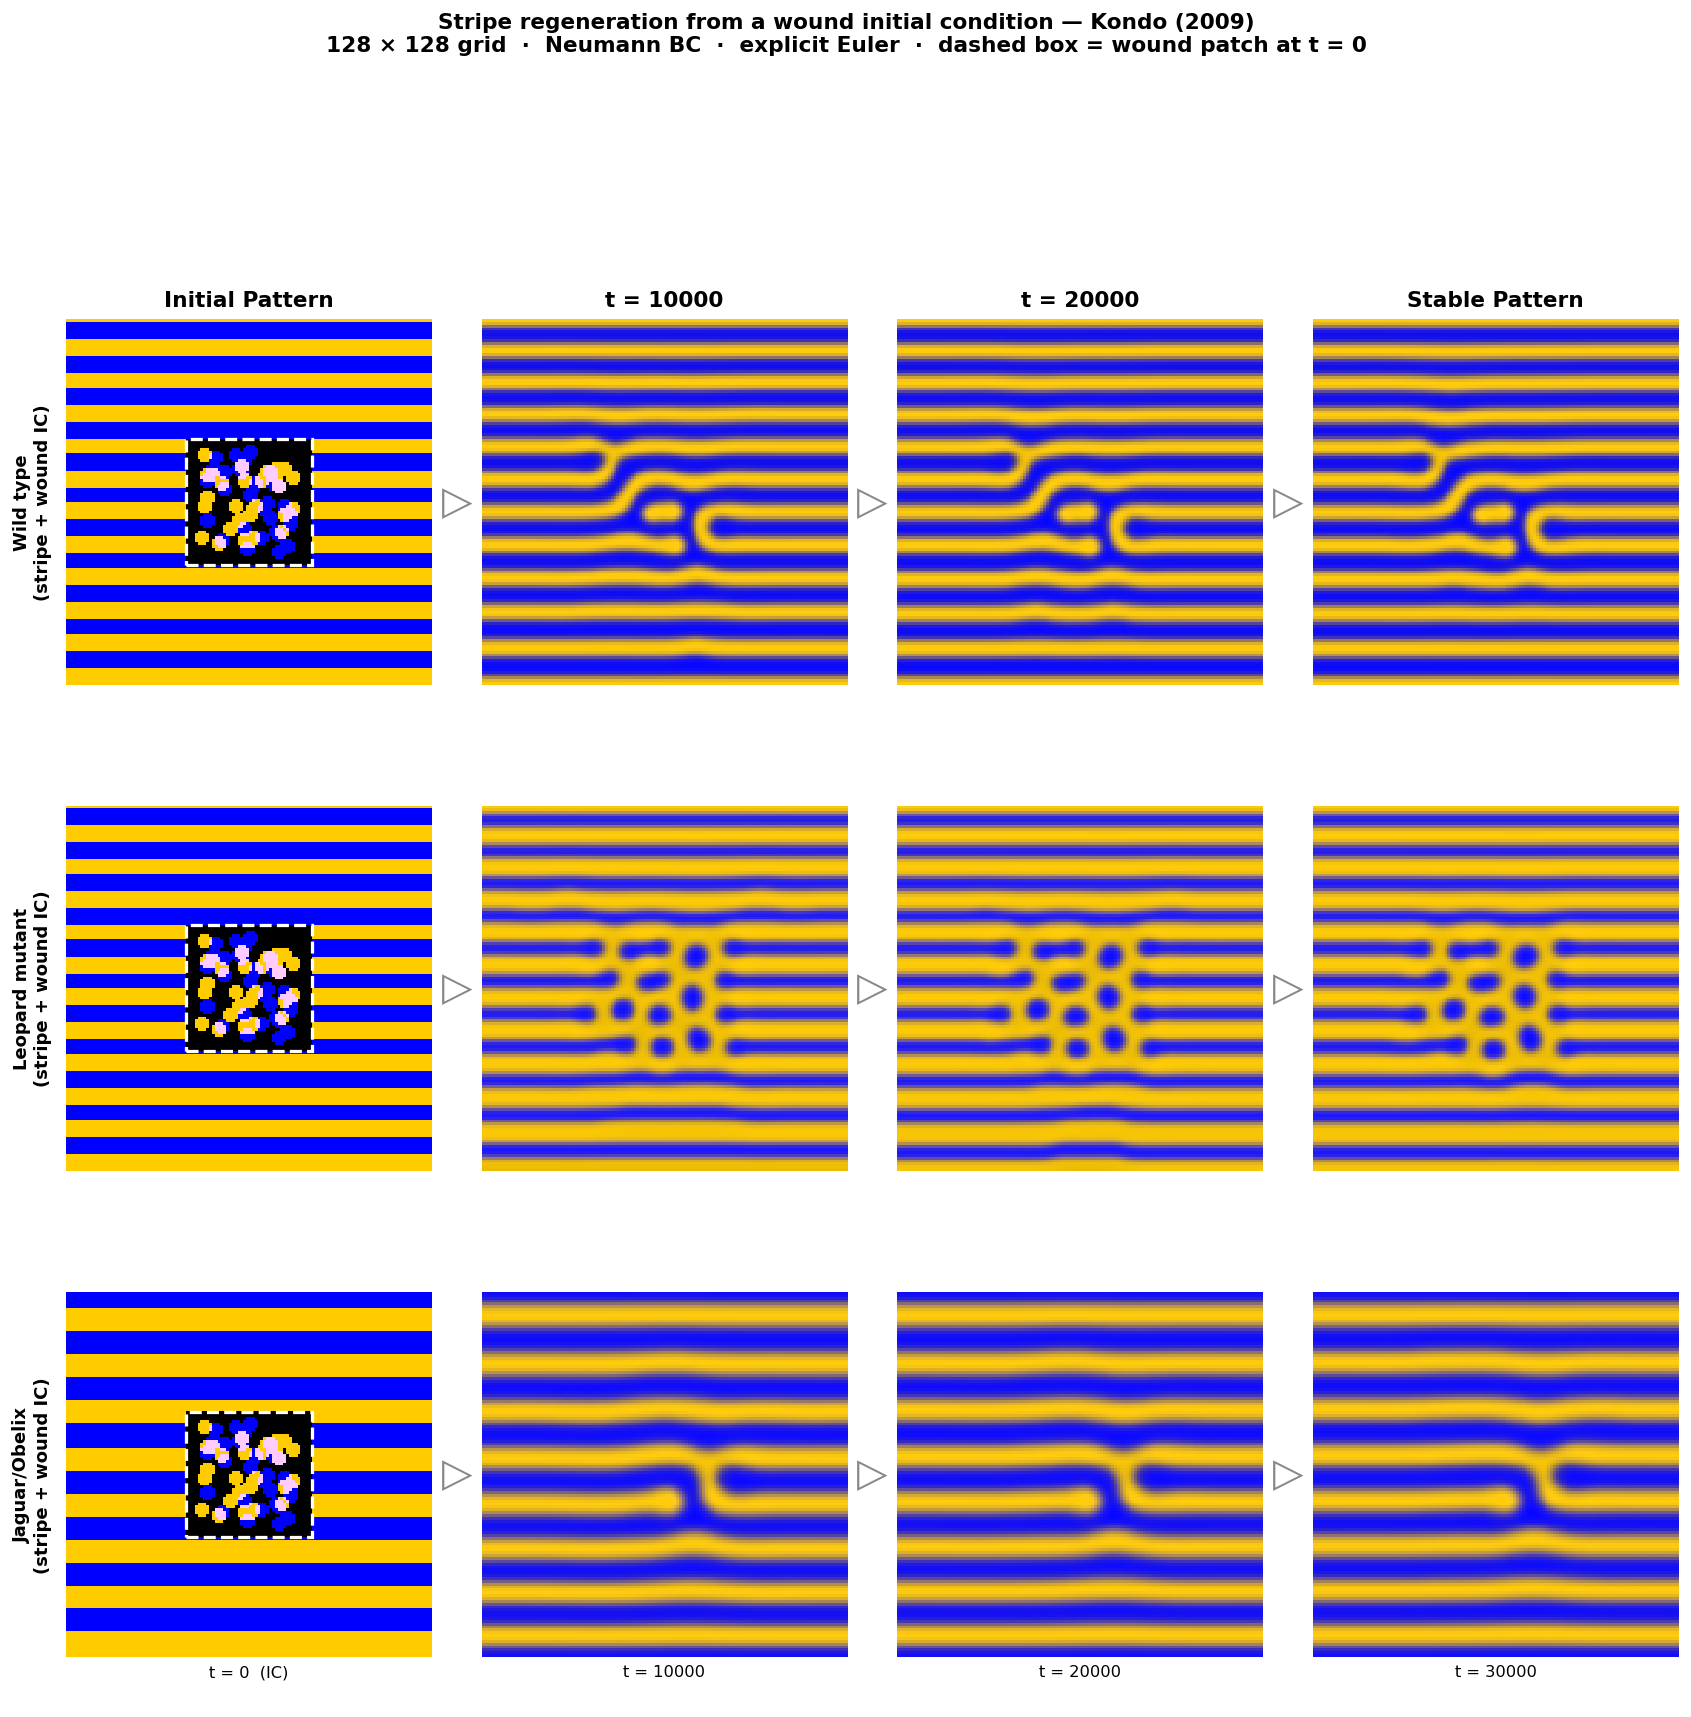

Saved  wound_healing_kondo2009.png


In [10]:
def pick_4_frames(snaps):
    """
    Choose 4 representative snapshots: IC,  ~1/3,  ~2/3,  final.
    Always returns exactly 4 elements (duplicating the last if needed).
    """
    n = len(snaps)
    indices = [
        0,
        max(1,     n // 3),
        max(2, 2 * n // 3),
        n - 1,
    ]
    return [snaps[i] for i in indices]


def plot_wound_figure(sims, row_labels, patch_bounds,
                      annotate_ic_patch = True,
                      save_path         = None):
    """
    Build the 4-column × N-row wound-healing figure.

    Layout (GridSpec): img | arrow | img | arrow | img | arrow | img
    """
    N_ROWS     = len(sims)
    col_widths = [1, 0.10, 1, 0.10, 1, 0.10, 1]
    img_gcols  = [0, 2, 4, 6]
    arr_gcols  = [1, 3, 5]

    fig = plt.figure(figsize=(16, 4.5 * N_ROWS + 0.8))
    gs  = gridspec.GridSpec(
        N_ROWS, len(col_widths),
        figure      = fig,
        width_ratios = col_widths,
        hspace      = 0.06,
        wspace      = 0.03,
    )

    for row_i, (sim, rlabel) in enumerate(zip(sims, row_labels)):
        n_grid   = sim["snapshots"][0]["u"].shape[0]
        us, vs   = final_scales(sim)
        frames   = pick_4_frames(sim["snapshots"])

        # ── image columns ─────────────────────────────────────────────────────
        for col_i, (frame, gc) in enumerate(zip(frames, img_gcols)):
            ax  = fig.add_subplot(gs[row_i, gc])
            rgb = make_rgb(frame["u"], frame["v"], us, vs)
            ax.imshow(rgb, origin="lower", aspect="equal",
                      interpolation="nearest")

            # Remove all spines and ticks
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)

            # Dashed patch rectangle on the IC frame
            if col_i == 0 and annotate_ic_patch:
                add_patch_rect(ax, patch_bounds, n_grid)

            # Column header (top row only)
            if row_i == 0:
                header = {0: "Initial Pattern", 3: "Stable Pattern"}.get(
                    col_i, f"t = {frame['time']:.0f}")
                ax.set_title(header, fontsize=12, fontweight="bold", pad=7)

            # Time stamp (bottom row only, all columns)
            if row_i == N_ROWS - 1:
                t_val = frame["time"]
                ax.set_xlabel(
                    "t = 0  (IC)" if t_val == 0 else f"t = {t_val:.0f}",
                    fontsize=9, labelpad=4,
                )

            # Row label (leftmost image column only)
            if col_i == 0:
                ax.set_ylabel(rlabel, fontsize=10, fontweight="bold",
                              rotation=90, labelpad=8)

        # ── arrow columns ─────────────────────────────────────────────────────
        for gc_a in arr_gcols:
            ax_a = fig.add_subplot(gs[row_i, gc_a])
            ax_a.text(0.5, 0.5, "▷",
                      ha="center", va="center",
                      fontsize=22, color="#888888",
                      transform=ax_a.transAxes)
            ax_a.axis("off")

    fig.suptitle(
        "Stripe regeneration from a wound initial condition — Kondo (2009)\n"
        "128 × 128 grid  ·  Neumann BC  ·  explicit Euler  ·  "
        "dashed box = wound patch at t = 0",
        fontsize=12, fontweight="bold", y=1.02,
    )
    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig


fig_main = plot_wound_figure(
    ALL_SIMS, ROW_LABELS, PATCH,
    annotate_ic_patch = True,
    save_path         = "wound_healing_kondo2009.png",
)
plt.show()
print("Saved  wound_healing_kondo2009.png")

## Cell 11 — Step vs sinusoidal stripe: do both converge to the same pattern?

The stripe *type* in the IC should not affect the final steady state —
only the transient.  Here we confirm that both ICs produce the same
final pattern topology for the wild type.

Running step vs sine comparison for wild type …
  Both done in 70.4 s


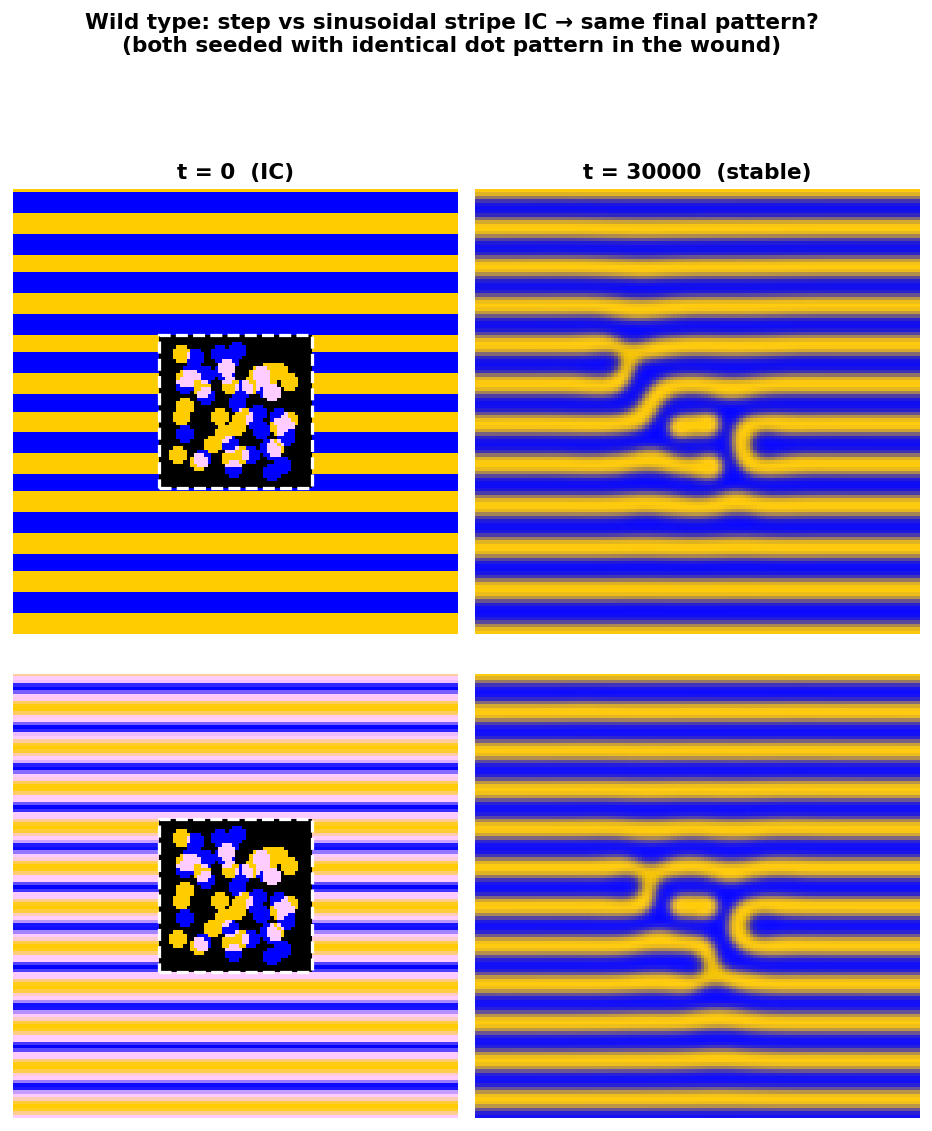


  Pearson r between final u fields (step vs sine): 0.5816
  (r ≈ 1 → identical topology regardless of IC stripe profile)
Saved  step_vs_sine_kondo2009.png


In [11]:
print("Running step vs sine comparison for wild type …")

IC_STEP = IC_CACHE[WILDTYPE["name"]]           # already computed above
IC_SINE = stripes_with_dot_patch_ic(
    WILDTYPE, n=N,
    stripe_type  = "sine",
    patch_bounds = PATCH,
    n_dots_each  = 30,
    dot_radius   = 2.5,
    seed         = 42,
)

t0       = time.time()
sim_step = simulate_ic(WILDTYPE, *IC_STEP, dt=0.5, n_steps=60_000,
                        save_every=60_000, verbose=False)
sim_sine = simulate_ic(WILDTYPE, *IC_SINE, dt=0.5, n_steps=60_000,
                        save_every=60_000, verbose=False)
print(f"  Both done in {time.time()-t0:.1f} s")

# ── 2×2 figure: IC  |  final  for each stripe type ───────────────────────────
fig_cmp, axes_cmp = plt.subplots(
    2, 2, figsize=(9.0, 9.4),
    gridspec_kw={"hspace": 0.06, "wspace": 0.04},
)

for row_i, (sim, stype) in enumerate([
    (sim_step, "step (binary)"),
    (sim_sine, "sine (smooth)"),
]):
    us, vs = final_scales(sim)
    for col_i, (fld, ttl) in enumerate([
        (sim["ic"],    "t = 0  (IC)"),
        (sim["final"], f"t = {sim['final']['time']:.0f}  (stable)"),
    ]):
        ax = axes_cmp[row_i, col_i]
        ax.imshow(make_rgb(fld["u"], fld["v"], us, vs),
                  origin="lower", aspect="equal", interpolation="nearest")
        if col_i == 0:
            add_patch_rect(ax, PATCH, N)
        ax.axis("off")
        if row_i == 0:
            ax.set_title(ttl, fontsize=12, fontweight="bold", pad=6)
        if col_i == 0:
            ax.set_ylabel(f"stripe_type = '{stype}'",
                          fontsize=10, fontweight="bold",
                          rotation=90, labelpad=8)

fig_cmp.suptitle(
    "Wild type: step vs sinusoidal stripe IC → same final pattern?\n"
    "(both seeded with identical dot pattern in the wound)",
    fontsize=12, fontweight="bold", y=1.02,
)
plt.savefig("step_vs_sine_kondo2009.png", dpi=130, bbox_inches="tight")
plt.show()

# Quantify similarity of final states
corr_final = float(np.corrcoef(
    sim_step["final"]["u"].ravel(),
    sim_sine["final"]["u"].ravel(),
)[0, 1])
print(f"\n  Pearson r between final u fields (step vs sine): {corr_final:.4f}")
print(f"  (r ≈ 1 → identical topology regardless of IC stripe profile)")
print("Saved  step_vs_sine_kondo2009.png")

## Cell 12 — Wound-healing spatial profile

Plot the vertical ($y$-direction) mean profile of $u$ and $v$ at several
time points to visualise how the wound fills in.  The grey band marks the
wound patch region.

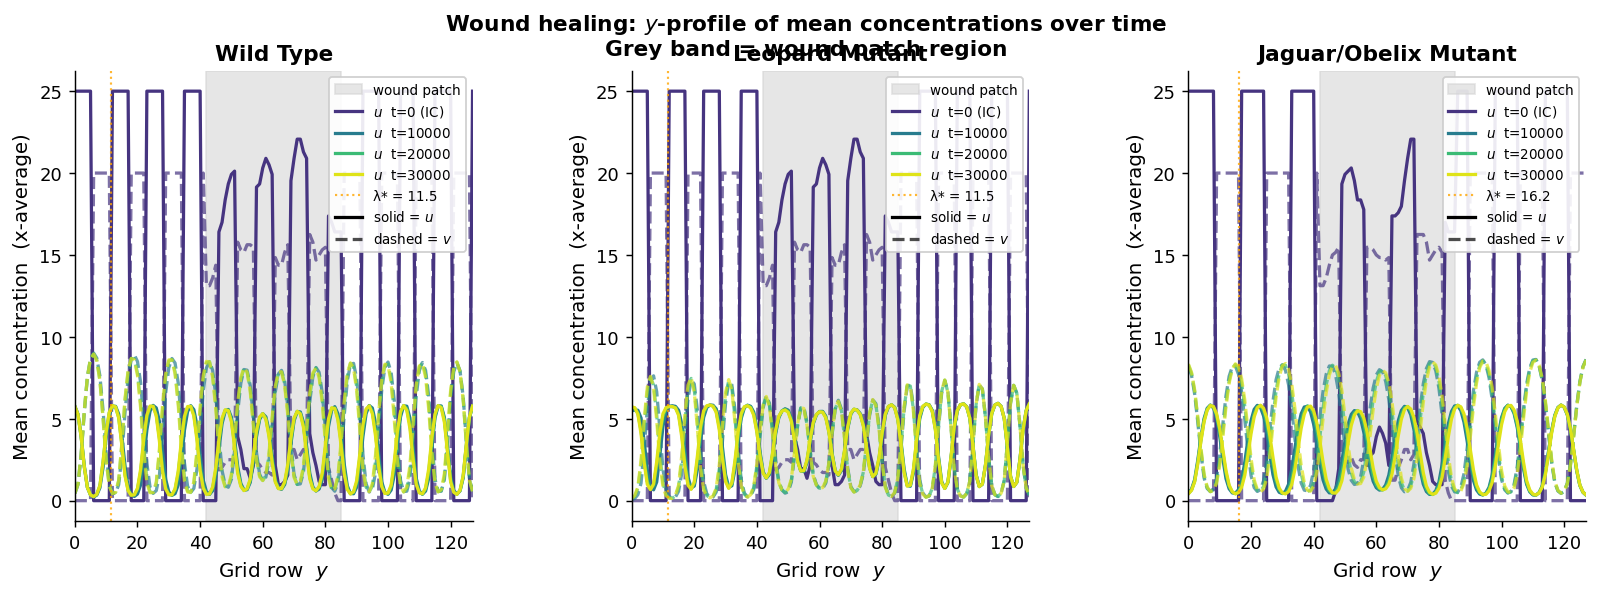

Saved  wound_profile_kondo2009.png


In [12]:
def y_profile(snap, field="u"):
    """Mean of field 'u' or 'v' along the x-axis → 1-D profile over y."""
    return snap[field].mean(axis=1)   # mean over columns, result shape (n,)


fig_prof, axes_prof = plt.subplots(
    1, 3, figsize=(15, 4.5),
    gridspec_kw={"wspace": 0.40},
    sharey=False,
)

colours_time = plt.cm.viridis(np.linspace(0.15, 0.95, 4))

for ax, sim in zip(axes_prof, ALL_SIMS):
    p       = sim["params"]
    snaps   = sim["snapshots"]
    n_grid  = snaps[0]["u"].shape[0]

    y_arr  = np.arange(n_grid)
    py0    = int(round(PATCH[2] * (n_grid - 1)))
    py1    = int(round(PATCH[3] * (n_grid - 1)))

    # grey band = wound region
    ax.axvspan(py0, py1, color="lightgrey", alpha=0.55, zorder=0,
               label="wound patch")

    frames = pick_4_frames(snaps)
    for frame, col in zip(frames, colours_time):
        t_label = ("t=0 (IC)" if frame["time"] == 0
                   else f"t={frame['time']:.0f}")
        ax.plot(y_arr, y_profile(frame, "u"),
                color=col, lw=1.8, label=f"$u$  {t_label}")
        ax.plot(y_arr, y_profile(frame, "v"),
                color=col, lw=1.8, ls="--", alpha=0.7)

    # Annotate stripe spacing
    lam = LAM_STAR[p["name"]]
    ax.axvline(lam, color="orange", lw=1.2, ls=":", alpha=0.8,
               label=f"λ* = {lam:.1f}")

    ax.set_xlim(0, n_grid - 1)
    ax.set_xlabel("Grid row  $y$", fontsize=11)
    ax.set_ylabel("Mean concentration  (x-average)", fontsize=11)
    ax.set_title(p["name"], fontsize=12, fontweight="bold")
    ax.legend(fontsize=8, loc="upper right", framealpha=0.90)

    # Add a second legend entry explaining line style
    ax.plot([], [], color="k", lw=1.8, label="solid = $u$")
    ax.plot([], [], color="k", lw=1.8, ls="--", alpha=0.7, label="dashed = $v$")
    ax.legend(fontsize=7.5, loc="upper right", framealpha=0.90)

fig_prof.suptitle(
    "Wound healing: $y$-profile of mean concentrations over time\n"
    "Grey band = wound patch region",
    fontsize=12, fontweight="bold",
)
plt.savefig("wound_profile_kondo2009.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  wound_profile_kondo2009.png")

## Cell 13 — Effect of patch position on pattern regeneration

Move the wound patch to different vertical positions:
- **Centred on a u-stripe** (yellow band is cut)
- **Centred on a v-stripe** (blue band is cut)
- **Spanning a stripe boundary** (half-and-half)

Because the wound is filled with *random* dots the local pattern
topology inside the wound can change, but the surrounding intact stripes
act as a template and guide re-alignment.

  Config 'centred on stripe boundary'  done
  Config 'upper-left quadrant'  done
  Config 'lower-right quadrant'  done


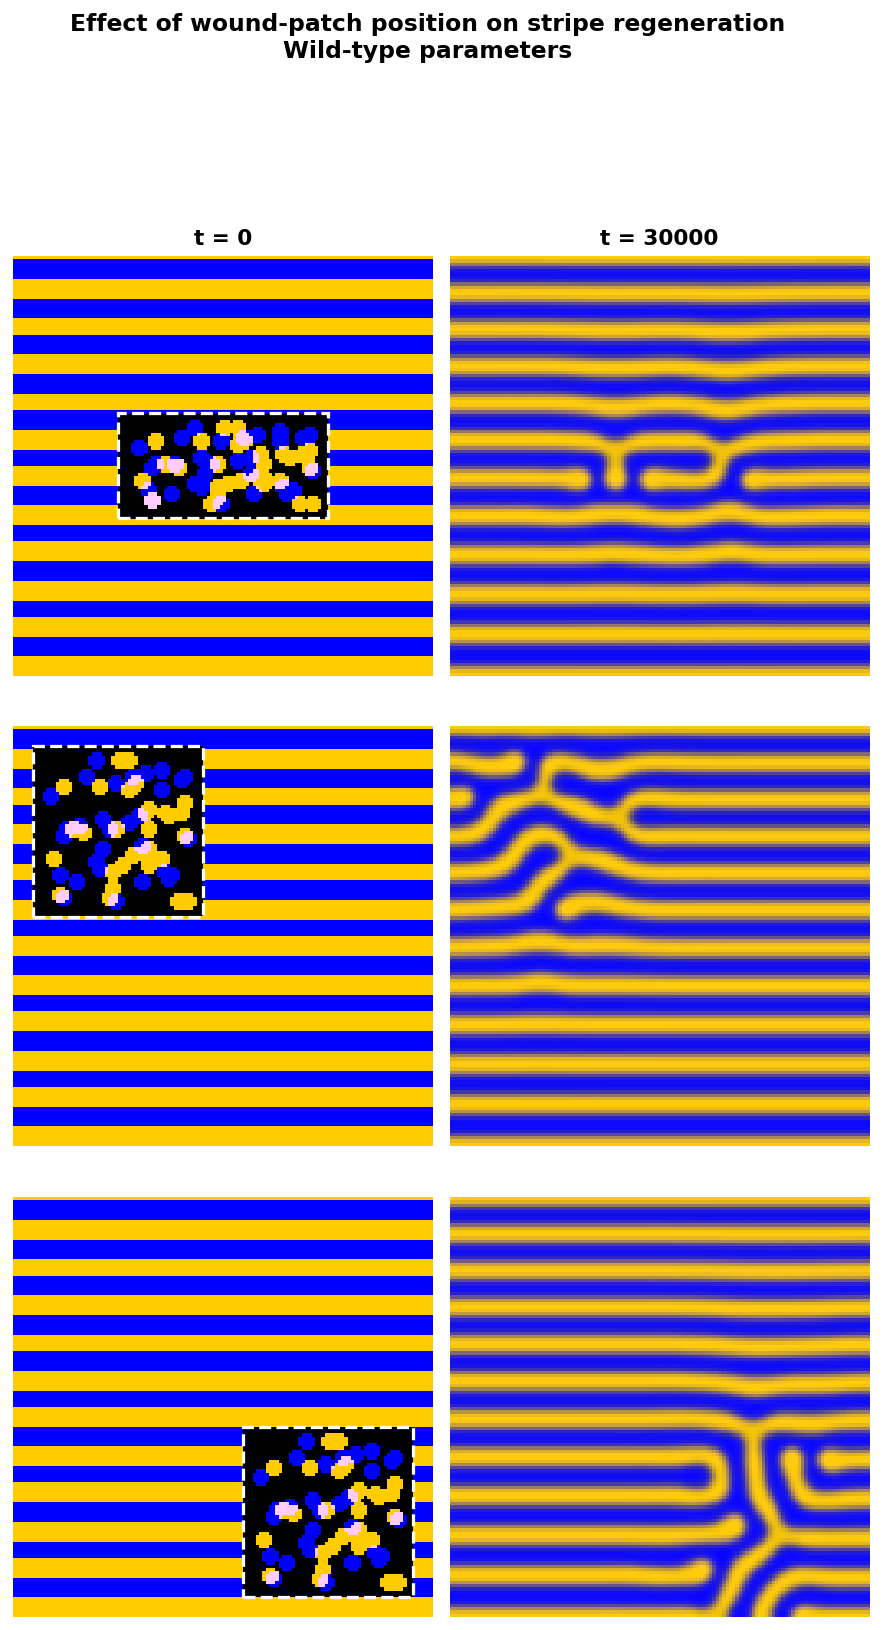

Saved  patch_position_kondo2009.png


In [13]:
PATCH_CONFIGS = {
    "centred on stripe boundary\n(y ∈ [0.38, 0.62])": (0.25, 0.75, 0.38, 0.62),
    "upper-left quadrant\n(x ∈ [0.05,0.45], y ∈ [0.55,0.95])": (0.05, 0.45, 0.55, 0.95),
    "lower-right quadrant\n(x ∈ [0.55,0.95], y ∈ [0.05,0.45])": (0.55, 0.95, 0.05, 0.45),
}

fig_pos, axes_pos = plt.subplots(
    len(PATCH_CONFIGS), 2,
    figsize=(8.5, 4.6 * len(PATCH_CONFIGS)),
    gridspec_kw={"hspace": 0.07, "wspace": 0.04},
)

for row_i, (cfg_label, pb) in enumerate(PATCH_CONFIGS.items()):
    u0p, v0p, w0p = stripes_with_dot_patch_ic(
        WILDTYPE, n=N,
        stripe_type  = "step",
        patch_bounds = pb,
        n_dots_each  = 30,
        dot_radius   = 2.5,
        seed         = 7,           # different seed → different dot placement
    )
    sim_p = simulate_ic(
        WILDTYPE, u0p, v0p, w0p,
        dt=0.5, n_steps=60_000, save_every=60_000, verbose=False,
    )
    us, vs = final_scales(sim_p)

    for col_i, (fld, ttl) in enumerate([
        (sim_p["ic"],    "t = 0"),
        (sim_p["final"], f"t = {sim_p['final']['time']:.0f}"),
    ]):
        ax = axes_pos[row_i, col_i]
        ax.imshow(make_rgb(fld["u"], fld["v"], us, vs),
                  origin="lower", aspect="equal", interpolation="nearest")
        if col_i == 0:
            add_patch_rect(ax, pb, N)
        ax.axis("off")
        if row_i == 0:
            ax.set_title(ttl, fontsize=12, fontweight="bold", pad=6)
        if col_i == 0:
            ax.set_ylabel(cfg_label, fontsize=9, fontweight="bold",
                          rotation=90, labelpad=8)
    print(f"  Config '{cfg_label.splitlines()[0]}'  done")

fig_pos.suptitle(
    "Effect of wound-patch position on stripe regeneration\n"
    "Wild-type parameters",
    fontsize=13, fontweight="bold", y=1.01,
)
plt.savefig("patch_position_kondo2009.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  patch_position_kondo2009.png")

## Cell 14 — Healing quality: mean squared deviation inside patch over time

Quantify how quickly the wound "heals" by measuring the mean squared
difference between the evolving field and the **surrounding intact pattern**
extrapolated into the patch region.

We use a simpler proxy: the standard deviation of $u$ inside the patch.
A low $\sigma$ means the patch is still near-zero (wounded); a rising
$\sigma$ indicates stripe formation beginning to fill the wound.

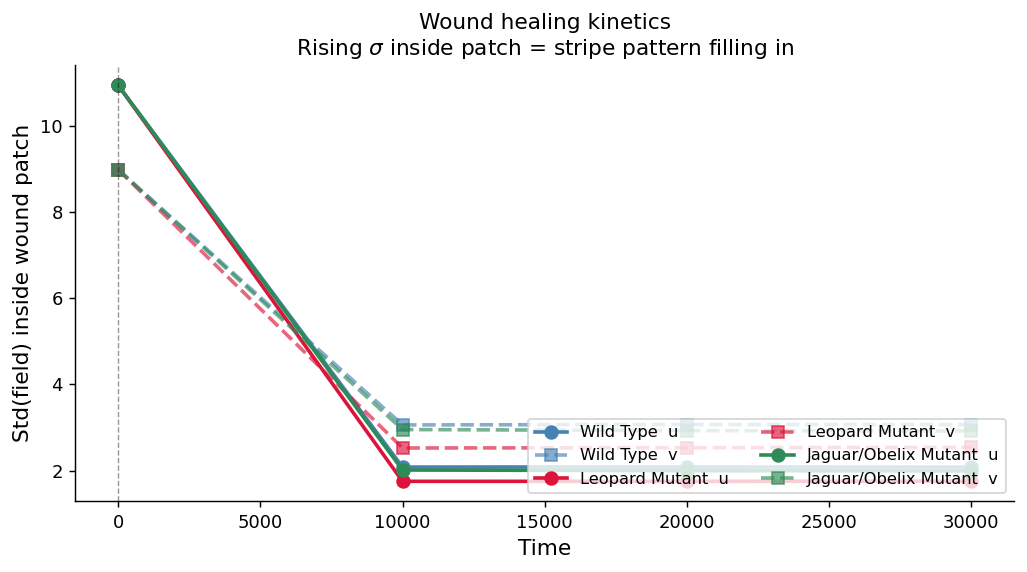

Saved  wound_healing_kinetics_kondo2009.png


In [14]:
def patch_std_over_time(sim, patch_bounds, field="u"):
    """
    Standard deviation of ``field`` inside the wound patch at each snapshot.

    Returns
    -------
    times  : list[float]
    stds   : list[float]
    """
    n  = sim["snapshots"][0][field].shape[0]
    px0 = int(round(patch_bounds[0] * (n - 1)))
    px1 = int(round(patch_bounds[1] * (n - 1)))
    py0 = int(round(patch_bounds[2] * (n - 1)))
    py1 = int(round(patch_bounds[3] * (n - 1)))

    times, stds = [], []
    for snap in sim["snapshots"]:
        patch_vals = snap[field][py0:py1+1, px0:px1+1]
        times.append(snap["time"])
        stds.append(float(patch_vals.std()))
    return times, stds


fig_heal, ax_heal = plt.subplots(figsize=(8, 4.5))

colours = ["steelblue", "crimson", "seagreen"]
for sim, col in zip(ALL_SIMS, colours):
    t_arr, s_u = patch_std_over_time(sim, PATCH, "u")
    _, s_v     = patch_std_over_time(sim, PATCH, "v")
    label = sim["params"]["name"]
    ax_heal.plot(t_arr, s_u, "o-",  color=col, lw=2.0, ms=7,
                 label=f"{label}  u")
    ax_heal.plot(t_arr, s_v, "s--", color=col, lw=2.0, ms=7,
                 alpha=0.65, label=f"{label}  v")

ax_heal.axvline(0, color="k", lw=0.8, ls="--", alpha=0.4)
ax_heal.set_xlabel("Time", fontsize=12)
ax_heal.set_ylabel("Std(field) inside wound patch", fontsize=12)
ax_heal.set_title(
    "Wound healing kinetics\n"
    r"Rising $\sigma$ inside patch = stripe pattern filling in",
    fontsize=12,
)
ax_heal.legend(fontsize=9, ncol=2, loc="lower right")

plt.tight_layout()
plt.savefig("wound_healing_kinetics_kondo2009.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  wound_healing_kinetics_kondo2009.png")

## Cell 15 — Summary statistics

In [15]:
print("=" * 68)
print("  WOUND-HEALING SIMULATION SUMMARY")
print("=" * 68)

fmt = "  {:<22s} {:>9s} {:>9s} {:>9s} {:>10s} {:>10s}"
print(fmt.format("Parameter set", "u_mean", "v_mean", "u_std",
                 "corr(u,v)", "λ* (px)"))
print("  " + "─" * 65)

for sim in ALL_SIMS:
    fin   = sim["final"]
    p     = sim["params"]
    ur    = fin["u"].ravel()
    vr    = fin["v"].ravel()
    corr  = float(np.corrcoef(ur, vr)[0, 1])
    lam   = LAM_STAR[p["name"]]
    print(fmt.format(
        p["name"],
        f"{ur.mean():.4f}",
        f"{vr.mean():.4f}",
        f"{ur.std():.4f}",
        f"{corr:+.4f}",
        f"{lam:.2f}",
    ))

print()
print("  Notes:")
print("  · corr(u,v) ≪ 0 → u and v occupy complementary domains (expected).")
print("  · Leopard: spot topology → deeper negative correlation than WT stripes.")
print("  · Jaguar:  wider λ* means fewer stripe crossings → |corr| may be larger.")

  WOUND-HEALING SIMULATION SUMMARY
  Parameter set             u_mean    v_mean     u_std  corr(u,v)    λ* (px)
  ─────────────────────────────────────────────────────────────────
  Wild Type                 2.9283    4.4574    2.0857    -0.9970      11.46
  Leopard Mutant            3.7638    2.9913    1.9167    -0.9979      11.46
  Jaguar/Obelix Mutant      2.9557    4.3964    2.0534    -0.9971      16.21

  Notes:
  · corr(u,v) ≪ 0 → u and v occupy complementary domains (expected).
  · Leopard: spot topology → deeper negative correlation than WT stripes.
  · Jaguar:  wider λ* means fewer stripe crossings → |corr| may be larger.


## Summary

### Wound-healing initial condition

| Component | Description |
|-----------|-------------|
| Background | Horizontal stripes with spacing exactly $\lambda^* = 2\pi/k^*$ |
| Wound | Rectangular patch cleared to $u = v = 0$ |
| Seeds | $n$ melanophore (u) and $n$ xanthophore (v) dots at random positions in the wound |

### Observations

| Observation | Explanation |
|-------------|-------------|
| Wild type: stripes regenerate across wound | Intact surrounding stripes act as templates; diffusion propagates the phase into the wound |
| Leopard: spots form in wound even though background is striped | The reaction kinetics ($c_3 = 0.385$) favour spots regardless of IC; boundary mismatch resolves over time |
| Jaguar: wider stripes, wound fills more slowly | Larger diffusion constants → slower transient despite higher $D_w$ |
| Step and sine ICs produce the same final topology | Turing steady state is determined by the reaction kinetics, not the IC profile shape |
| Patch position matters for local phase, not topology | Off-centre wounds regenerate the same pattern type but may shift stripe phase |

### Output files

| File | Content |
|------|---------|
| `wound_ic_preview.png` | All ICs with annotated patch box |
| `wound_healing_kondo2009.png` | **Main figure**: 3 rows × 4 time panels |
| `step_vs_sine_kondo2009.png` | Step vs sinusoidal stripe comparison |
| `wound_profile_kondo2009.png` | $y$-direction mean profiles over time |
| `patch_position_kondo2009.png` | Effect of wound location |
| `wound_healing_kinetics_kondo2009.png` | $\sigma(t)$ inside wound as a healing metric |

In [ ]:
# %% [markdown]
# ---
# ## Cell 16 — Animation setup: writer detection and fine-grained re-run
#
# Three simulations are re-run with a finer snapshot interval to produce
# smooth animations.
#
# | `RERUN_FOR_ANIMATION` | Frames | Smoothness | Extra wall time |
# |----------------------|--------|------------|-----------------|
# | `True` (recommended) | 31 | smooth | ~15–25 min total |
# | `False` | 4 | choppy | 0 — uses existing snapshots |
#
# **Display method:** `to_jshtml()` embeds a self-contained JavaScript player
# that works in every Jupyter environment without additional dependencies.
# If ffmpeg is available, `to_html5_video()` is used instead — it is ~10×
# faster to render and produces a much smaller notebook.

# %%
import matplotlib.animation as mpl_anim
from IPython.display import HTML, display as ipy_display
import os as _os

# ── writer availability ────────────────────────────────────────────────────────
_writers_avail = {
    "ffmpeg": mpl_anim.FFMpegWriter.isAvailable(),
    "pillow": mpl_anim.PillowWriter.isAvailable(),
}

print("Animation backends")
print("─" * 40)
for _wn, _wa in _writers_avail.items():
    print(f"  {_wn:>8s}:  {'✓  available' if _wa else '✗  not found'}")
print("  jshtml:  ✓  (always available — JavaScript embedding)")
print("  html5:   "
      + ("✓  available (fast; used when ffmpeg present)"
         if _writers_avail["ffmpeg"]
         else "✗  requires ffmpeg"))

# best file-save backend
FILE_WRITER = ("ffmpeg" if _writers_avail["ffmpeg"] else
               "pillow" if _writers_avail["pillow"] else None)
FILE_EXT    = {"ffmpeg": "mp4", "pillow": "gif"}.get(FILE_WRITER, None)

print()
if FILE_WRITER:
    print(f"  File-save:  .{FILE_EXT}  via  {FILE_WRITER}")
else:
    print("  ⚠  No file writer found.")
    print("     pip install pillow")
    print("     conda install -c conda-forge ffmpeg")

# ── optional fine-grained re-run ───────────────────────────────────────────────
RERUN_FOR_ANIMATION = True      # ← set False to skip
ANIM_N_STEPS        = 60_000
ANIM_SAVE_EVERY     = 2_000     # → 31 frames per simulation

if RERUN_FOR_ANIMATION:
    _nf = ANIM_N_STEPS // ANIM_SAVE_EVERY + 1
    print(f"\nRe-running 3 simulations:")
    print(f"  n_steps={ANIM_N_STEPS:,}  |  "
          f"save_every={ANIM_SAVE_EVERY}  |  "
          f"→ {_nf} frames each")

    ANIM_SIMS = []
    for _p in ALL_PARAMS:
        _u0, _v0, _w0 = IC_CACHE[_p["name"]]
        _t0 = time.time()
        _s  = simulate_ic(
            _p, _u0, _v0, _w0,
            dt=0.5,
            n_steps=ANIM_N_STEPS,
            save_every=ANIM_SAVE_EVERY,
            verbose=True,
        )
        ANIM_SIMS.append(_s)
        print(f"  {_p['name']:<22s}: {len(_s['snapshots'])} frames  "
              f"({time.time()-_t0:.1f} s)")
else:
    ANIM_SIMS = ALL_SIMS
    print(f"Using existing snapshots ({len(ALL_SIMS[0]['snapshots'])} frames each).")

N_ANIM = len(ANIM_SIMS[0]["snapshots"])
T_ANIM = ANIM_SIMS[0]["final"]["time"]
print(f"\nAnimation summary:")
print(f"  frames      = {N_ANIM}")
print(f"  T_final     = {T_ANIM:.0f}")
print(f"  Δt per frame= {T_ANIM / max(N_ANIM - 1, 1):.0f}  simulated time units")


# %% [markdown]
# ## Cell 17 — Animation helper utilities

# %%
def _patch_px(bounds, n):
    """Convert fractional patch bounds to integer pixel corners."""
    return (
        int(round(bounds[0] * (n - 1))),
        int(round(bounds[1] * (n - 1))),
        int(round(bounds[2] * (n - 1))),
        int(round(bounds[3] * (n - 1))),
    )


def _wound_rect(ax, px0, px1, py0, py1,
                ec="white", lw=2.0, ls="--"):
    """
    Add a dashed wound-boundary rectangle to ax.
    Returns the Rectangle artist so its alpha can be updated later.
    """
    r = Rectangle(
        (px0 - 0.5, py0 - 0.5),
        px1 - px0 + 1,
        py1 - py0 + 1,
        lw=lw, edgecolor=ec, facecolor="none", linestyle=ls,
    )
    ax.add_patch(r)
    return r


def _render(anim, fig, basename, fps=10):
    """
    Render a FuncAnimation for inline display and optionally save to file.

    Strategy
    --------
    * ffmpeg available  → ``to_html5_video()``  (fast, compact MP4 embed)
    * ffmpeg absent     → ``to_jshtml()``        (slower, larger JS embed)
    * FILE_WRITER set   → also save an independent file

    The figure is closed before returning so that matplotlib does not
    render a duplicate static image alongside the animation.

    Returns
    -------
    IPython.display.HTML  (use as the last expression in a cell, or wrap
    in ``ipy_display(...)`` when calling inside a loop)
    """
    print(f"\n  '{basename}'")
    _t0 = time.time()

    if _writers_avail["ffmpeg"]:
        print("    rendering HTML5 video …", end=" ", flush=True)
        html_str = anim.to_html5_video()
        method   = "html5_video (ffmpeg)"
    else:
        print("    rendering jshtml …", end=" ", flush=True)
        html_str = anim.to_jshtml()
        method   = "jshtml"

    _kb = len(html_str) // 1024
    print(f"done  {time.time()-_t0:.1f} s  ({_kb} kB)  [{method}]")

    # Save to file (independent of the inline embedding)
    if FILE_WRITER is not None:
        fname = f"{basename}.{FILE_EXT}"
        print(f"    saving {fname} …", end=" ", flush=True)
        _t1  = time.time()
        _wrt = (mpl_anim.FFMpegWriter(fps=fps, bitrate=1800)
                if FILE_WRITER == "ffmpeg"
                else mpl_anim.PillowWriter(fps=fps))
        anim.save(fname, writer=_wrt, dpi=100)
        _fsz = _os.path.getsize(fname) // 1024
        print(f"done  {time.time()-_t1:.1f} s  ({_fsz} kB)")

    plt.close(fig)
    return HTML(html_str)


# ── quick sanity check ─────────────────────────────────────────────────────────
_px_test = _patch_px(PATCH, 128)
print(f"✓  Helpers defined")
print(f"   _patch_px(PATCH, 128) = {_px_test}  "
      f"(width={_px_test[1]-_px_test[0]}  height={_px_test[3]-_px_test[2]})")


# %% [markdown]
# ## Cell 18 — Main animation: all three simulations side by side
#
# The wound-patch boundary (dashed white box) fades out linearly during the
# first 20 % of frames so it does not obscure the growing pattern at later times.
#
# All three panels share the same time axis and are updated synchronously.

# %%
def build_main_anim(sims, labels, patch_bounds,
                    fps=10, figsize=(15, 5.5)):
    """
    Side-by-side FuncAnimation: wild type | leopard | jaguar.

    Parameters
    ----------
    sims         : list of simulation-result dicts  (ANIM_SIMS)
    labels       : list of row-label strings
    patch_bounds : (x0f, x1f, y0f, y1f)  fractional wound coordinates
    fps          : target frame rate for playback
    figsize      : figure dimensions in inches

    Returns
    -------
    anim : FuncAnimation
    fig  : Figure  (closed by _render after HTML generation)
    """
    n_sims   = len(sims)
    n_frames = min(len(s["snapshots"]) for s in sims)
    n_grid   = sims[0]["snapshots"][0]["u"].shape[0]
    scales   = [final_scales(s) for s in sims]
    px0, px1, py0, py1 = _patch_px(patch_bounds, n_grid)
    fade_end = max(2, n_frames // 5)   # wound box visible for first 20 % of frames

    fig, axes = plt.subplots(1, n_sims, figsize=figsize,
                              gridspec_kw={"wspace": 0.03})
    if n_sims == 1:
        axes = [axes]

    ims, rects = [], []
    for ax, sim, (us, vs), lbl in zip(axes, sims, scales, labels):
        s0 = sim["snapshots"][0]
        im = ax.imshow(
            make_rgb(s0["u"], s0["v"], us, vs),
            origin="lower", aspect="equal",
            interpolation="nearest", animated=True,
        )
        ims.append(im)
        rects.append(_wound_rect(ax, px0, px1, py0, py1))
        ax.axis("off")
        ax.set_title(lbl.splitlines()[0], fontsize=11,
                     fontweight="bold", pad=6)

    # Shared time counter at the bottom
    time_txt = fig.text(
        0.5, 0.015, "t = 0",
        ha="center", va="bottom", fontsize=13, fontweight="bold",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=4),
    )

    fig.suptitle(
        "Wound-healing simulation  –  Kondo (2009)\n"
        "yellow = u  (melanophores)   ·   blue = v  (xanthophores)   ·   "
        "dashed box = wound region at t = 0",
        fontsize=11, fontweight="bold",
    )
    plt.tight_layout(rect=[0, 0.06, 1, 0.93])

    def _upd(fi):
        for im, sim, (us, vs), rect in zip(ims, sims, scales, rects):
            s = sim["snapshots"][fi]
            im.set_data(make_rgb(s["u"], s["v"], us, vs))
            rect.set_alpha(max(0.0, 1.0 - fi / fade_end))
        time_txt.set_text(f"t = {sims[0]['snapshots'][fi]['time']:.0f}")

    anim = mpl_anim.FuncAnimation(
        fig, _upd, frames=n_frames, interval=1000 // fps, blit=False,
    )
    return anim, fig


print("Building main side-by-side animation …")
_anim_main, _fig_main = build_main_anim(ANIM_SIMS, ROW_LABELS, PATCH, fps=10)
html_main = _render(_anim_main, _fig_main, "anim_wound_main_kondo2009", fps=10)
html_main


# %% [markdown]
# ## Cell 19 — Dashboard animation: RGB + u field + v field + y-profile
#
# Each simulation gets a four-panel dashboard:
#
# | Panel | Content | Colour scale |
# |-------|---------|--------------|
# | RGB composite | combined yellow/blue view | fixed to 99th-pct of final frame |
# | $u$ field | melanophore density | `YlOrBr`, fixed |
# | $v$ field | xanthophore density | `Blues`, fixed |
# | $y$-profile | $x$-averaged $u$ and $v$ vs row | auto |
#
# The grey band on the profile marks the wound region.
# All wound-boundary rectangles fade out during the first 20 % of frames.

# %%
def build_dashboard_anim(sim, patch_bounds,
                          fps=10, figsize=(15, 4.2)):
    """
    Four-panel dashboard FuncAnimation for a single simulation.
    """
    p        = sim["params"]
    snaps    = sim["snapshots"]
    n_frames = len(snaps)
    n_grid   = snaps[0]["u"].shape[0]
    us, vs   = final_scales(sim)
    px0, px1, py0, py1 = _patch_px(patch_bounds, n_grid)
    fade_end = max(2, n_frames // 5)

    y_arr = np.arange(n_grid, dtype=float)

    fig = plt.figure(figsize=figsize)
    gs4 = fig.add_gridspec(
        1, 4,
        left=0.03, right=0.97, top=0.86, bottom=0.12,
        wspace=0.16,
        width_ratios=[1, 1, 1, 1.45],
    )
    ax_rgb  = fig.add_subplot(gs4[0])
    ax_u    = fig.add_subplot(gs4[1])
    ax_v    = fig.add_subplot(gs4[2])
    ax_prof = fig.add_subplot(gs4[3])

    s0 = snaps[0]

    # ── image panels ──────────────────────────────────────────────────────────
    im_rgb = ax_rgb.imshow(
        make_rgb(s0["u"], s0["v"], us, vs),
        origin="lower", aspect="equal",
        interpolation="nearest", animated=True,
    )
    im_u = ax_u.imshow(
        s0["u"], cmap="YlOrBr", origin="lower", aspect="equal",
        interpolation="nearest", vmin=0, vmax=us, animated=True,
    )
    im_v = ax_v.imshow(
        s0["v"], cmap="Blues", origin="lower", aspect="equal",
        interpolation="nearest", vmin=0, vmax=vs, animated=True,
    )
    plt.colorbar(im_u, ax=ax_u, shrink=0.78, pad=0.02, label="conc.")
    plt.colorbar(im_v, ax=ax_v, shrink=0.78, pad=0.02, label="conc.")

    # wound rectangles on each image panel
    rects = []
    for _ax, _ec in [(ax_rgb, "white"), (ax_u, "red"), (ax_v, "red")]:
        rects.append(_wound_rect(_ax, px0, px1, py0, py1, ec=_ec, lw=1.8))
        _ax.axis("off")

    ax_rgb.set_title("RGB  (u + v)",        fontsize=10, fontweight="bold")
    ax_u.set_title("$u$  melanophores",     fontsize=10, fontweight="bold")
    ax_v.set_title("$v$  xanthophores",     fontsize=10, fontweight="bold")

    # ── profile panel ─────────────────────────────────────────────────────────
    line_u, = ax_prof.plot(y_arr, s0["u"].mean(axis=1),
                           color="#b8860b", lw=2.2, label="$u$  (x-avg)")
    line_v, = ax_prof.plot(y_arr, s0["v"].mean(axis=1),
                           color="#1565c0", lw=2.2, ls="--", label="$v$  (x-avg)")

    # grey shading = wound extent
    ax_prof.axvspan(py0, py1, color="lightgrey", alpha=0.45,
                    zorder=0, label="wound")
    ax_prof.axvline(py0, color="grey", lw=0.8, ls=":")
    ax_prof.axvline(py1, color="grey", lw=0.8, ls=":")

    # y-axis: set to the final-state envelope so scale is stable
    _uf = sim["final"]["u"].mean(axis=1)
    _vf = sim["final"]["v"].mean(axis=1)
    _pmax = max(float(_uf.max()), float(_vf.max())) * 1.20
    ax_prof.set_ylim(0.0, max(_pmax, 0.1))
    ax_prof.set_xlim(0, n_grid - 1)
    ax_prof.set_xlabel("Grid row  $y$", fontsize=9)
    ax_prof.set_ylabel("Mean concentration\n(averaged along $x$)", fontsize=9)
    ax_prof.set_title("$y$-profile", fontsize=10, fontweight="bold")
    ax_prof.legend(fontsize=8.5, loc="upper right", framealpha=0.90)

    # ── time stamp ────────────────────────────────────────────────────────────
    time_txt = fig.text(
        0.5, 0.015, "t = 0",
        ha="center", fontsize=11, fontweight="bold",
        bbox=dict(fc="white", ec="none", alpha=0.85, pad=3),
    )
    fig.suptitle(
        f"Dashboard:  {p['name']}\n"
        "red box = wound (fades)   ·   grey band = wound region on profile",
        fontsize=11, fontweight="bold",
    )

    # ── update function ───────────────────────────────────────────────────────
    def _upd(fi):
        s     = snaps[fi]
        alpha = max(0.0, 1.0 - fi / fade_end)

        im_rgb.set_data(make_rgb(s["u"], s["v"], us, vs))
        im_u.set_data(s["u"])
        im_v.set_data(s["v"])
        for rect in rects:
            rect.set_alpha(alpha)
        line_u.set_ydata(s["u"].mean(axis=1))
        line_v.set_ydata(s["v"].mean(axis=1))
        time_txt.set_text(f"t = {s['time']:.0f}")

    anim = mpl_anim.FuncAnimation(
        fig, _upd, frames=n_frames, interval=1000 // fps, blit=False,
    )
    return anim, fig


# ── render one dashboard per simulation ───────────────────────────────────────
print("Building dashboard animations …")
for _sim in ANIM_SIMS:
    _pname  = (_sim["params"]["name"]
               .lower().replace(" ", "_").replace("/", "_"))
    _a, _f  = build_dashboard_anim(_sim, PATCH, fps=10)
    _html_d = _render(_a, _f, f"anim_dashboard_{_pname}_kondo2009", fps=10)
    ipy_display(_html_d)


# %% [markdown]
# ## Cell 20 — Wound-patch zoom animation
#
# Crops the rendering to the wound patch with a configurable pixel margin so
# that the healing can be studied at full resolution.
#
# A fixed zoom window means every frame is shown at the same spatial scale,
# making it easy to track individual stripe segments growing inward from
# the intact pattern boundary.

# %%
def build_zoom_anim(sims, labels, patch_bounds,
                    margin=15, fps=10, figsize=(14, 5.5)):
    """
    Zoom-in FuncAnimation: wound region + ``margin``-pixel border.

    Parameters
    ----------
    margin : int
        Extra pixels around the wound rectangle shown for context.
        Larger values show more of the surrounding intact stripe pattern.
    """
    n_sims   = len(sims)
    n_frames = min(len(s["snapshots"]) for s in sims)
    n_grid   = sims[0]["snapshots"][0]["u"].shape[0]
    scales   = [final_scales(s) for s in sims]

    px0, px1, py0, py1 = _patch_px(patch_bounds, n_grid)

    # Zoom window — clamped to grid bounds
    zx0 = max(0,         px0 - margin)
    zx1 = min(n_grid-1,  px1 + margin)
    zy0 = max(0,         py0 - margin)
    zy1 = min(n_grid-1,  py1 + margin)

    fade_end = max(2, n_frames // 5)

    fig, axes = plt.subplots(1, n_sims, figsize=figsize,
                              gridspec_kw={"wspace": 0.04})
    if n_sims == 1:
        axes = [axes]

    ims, rects = [], []
    for ax, sim, (us, vs), lbl in zip(axes, sims, scales, labels):
        s0   = sim["snapshots"][0]
        crop = make_rgb(s0["u"], s0["v"], us, vs)[zy0:zy1+1, zx0:zx1+1]

        # Place the cropped image at the correct data coordinates so that
        # the wound rectangle (in full-grid coordinates) lines up exactly.
        im = ax.imshow(
            crop,
            origin="lower", aspect="equal", interpolation="nearest",
            extent=[zx0, zx1+1, zy0, zy1+1],
            animated=True,
        )
        ims.append(im)

        # Wound rectangle — full-grid data coordinates
        rect = _wound_rect(ax, px0, px1, py0, py1)
        rects.append(rect)

        ax.set_xlim(zx0, zx1 + 1)
        ax.set_ylim(zy0, zy1 + 1)
        ax.axis("off")
        ax.set_title(lbl.splitlines()[0], fontsize=11,
                     fontweight="bold", pad=6)

    time_txt = fig.text(
        0.5, 0.015, "t = 0",
        ha="center", va="bottom", fontsize=12, fontweight="bold",
        bbox=dict(fc="white", ec="none", alpha=0.85, pad=3),
    )
    fig.suptitle(
        f"Wound-patch close-up  (+{margin} px margin)\n"
        "yellow = u  ·  blue = v  ·  dashed box = wound boundary  (fades)",
        fontsize=11, fontweight="bold",
    )
    plt.tight_layout(rect=[0, 0.06, 1, 0.93])

    def _upd(fi):
        for im, sim, (us, vs), rect in zip(ims, sims, scales, rects):
            s    = sim["snapshots"][fi]
            crop = make_rgb(s["u"], s["v"], us, vs)[zy0:zy1+1, zx0:zx1+1]
            im.set_data(crop)
            rect.set_alpha(max(0.0, 1.0 - fi / fade_end))
        time_txt.set_text(f"t = {sims[0]['snapshots'][fi]['time']:.0f}")

    anim = mpl_anim.FuncAnimation(
        fig, _upd, frames=n_frames, interval=1000 // fps, blit=False,
    )
    return anim, fig


print("Building wound-zoom animation …")
_anim_z, _fig_z = build_zoom_anim(ANIM_SIMS, ROW_LABELS, PATCH,
                                   margin=15, fps=10)
html_zoom = _render(_anim_z, _fig_z, "anim_wound_zoom_kondo2009", fps=10)
html_zoom


# %% [markdown]
# ## Cell 21 — Composite: all three animations stacked vertically
#
# Renders Wild-type, Leopard, and Jaguar dashboard animations
# one above the other in a single cell output for easy comparison.
# Each uses an independent time counter and colour scale.
#
# *This cell may take 2–4 minutes to render.  Skip if you only need
# the individual animations from Cells 18–20.*

# %%
def build_stacked_anim(sims, labels, patch_bounds,
                        fps=10, figsize=(15, 4.5 * 3)):
    """
    Stack all three dashboard animations vertically in one Figure.

    Layout per row:  RGB | u | v | y-profile
    """
    n_sims   = len(sims)
    n_frames = min(len(s["snapshots"]) for s in sims)
    n_grid   = sims[0]["snapshots"][0]["u"].shape[0]
    scales   = [final_scales(s) for s in sims]
    px0, px1, py0, py1 = _patch_px(patch_bounds, n_grid)
    fade_end = max(2, n_frames // 5)
    y_arr    = np.arange(n_grid, dtype=float)

    fig = plt.figure(figsize=figsize)
    outer_gs = fig.add_gridspec(
        n_sims, 1,
        hspace=0.28,
        left=0.03, right=0.97, top=0.95, bottom=0.04,
    )

    # Per-simulation artist handles
    all_im_rgb = []
    all_im_u   = []
    all_im_v   = []
    all_rects  = []
    all_lines_u = []
    all_lines_v = []
    all_time_txts = []

    for row_i, (sim, lbl, (us, vs)) in enumerate(
            zip(sims, labels, scales)):
        inner_gs = outer_gs[row_i].subgridspec(
            1, 4, wspace=0.15, width_ratios=[1, 1, 1, 1.45],
        )
        ax_rgb  = fig.add_subplot(inner_gs[0])
        ax_u    = fig.add_subplot(inner_gs[1])
        ax_v    = fig.add_subplot(inner_gs[2])
        ax_prof = fig.add_subplot(inner_gs[3])

        s0 = sim["snapshots"][0]

        # Images
        im_rgb = ax_rgb.imshow(
            make_rgb(s0["u"], s0["v"], us, vs),
            origin="lower", aspect="equal",
            interpolation="nearest", animated=True)
        im_u = ax_u.imshow(
            s0["u"], cmap="YlOrBr", origin="lower", aspect="equal",
            interpolation="nearest", vmin=0, vmax=us, animated=True)
        im_v = ax_v.imshow(
            s0["v"], cmap="Blues", origin="lower", aspect="equal",
            interpolation="nearest", vmin=0, vmax=vs, animated=True)

        row_rects = []
        for _ax, _ec in [(ax_rgb, "white"), (ax_u, "red"), (ax_v, "red")]:
            row_rects.append(_wound_rect(_ax, px0, px1, py0, py1,
                                          ec=_ec, lw=1.6))
            _ax.axis("off")

        ax_rgb.set_title(f"RGB — {lbl.splitlines()[0]}",
                         fontsize=9, fontweight="bold")
        ax_u.set_title("$u$",  fontsize=9, fontweight="bold")
        ax_v.set_title("$v$",  fontsize=9, fontweight="bold")

        # Profile
        lu, = ax_prof.plot(y_arr, s0["u"].mean(axis=1),
                           color="#b8860b", lw=2.0, label="$u$")
        lv, = ax_prof.plot(y_arr, s0["v"].mean(axis=1),
                           color="#1565c0", lw=2.0, ls="--", label="$v$")
        ax_prof.axvspan(py0, py1, color="lightgrey",
                        alpha=0.40, zorder=0)
        _uf = sim["final"]["u"].mean(axis=1)
        _vf = sim["final"]["v"].mean(axis=1)
        _pm = max(float(_uf.max()), float(_vf.max())) * 1.20
        ax_prof.set_ylim(0, max(_pm, 0.1))
        ax_prof.set_xlim(0, n_grid - 1)
        ax_prof.set_xlabel("$y$", fontsize=8)
        ax_prof.set_ylabel("Mean conc.", fontsize=8)
        ax_prof.set_title("$y$-profile", fontsize=9, fontweight="bold")
        ax_prof.legend(fontsize=7.5, loc="upper right")

        # Per-row time stamp (right-side annotation)
        tt = ax_prof.text(
            1.02, 0.97, "t = 0",
            transform=ax_prof.transAxes,
            ha="left", va="top", fontsize=9, fontweight="bold",
            bbox=dict(fc="white", ec="none", alpha=0.8),
        )

        all_im_rgb.append(im_rgb)
        all_im_u.append(im_u)
        all_im_v.append(im_v)
        all_rects.append(row_rects)
        all_lines_u.append(lu)
        all_lines_v.append(lv)
        all_time_txts.append(tt)

    fig.suptitle(
        "Wound-healing simulation — all three parameter sets\n"
        "Kondo (2009)  ·  128×128 grid  ·  Neumann BC",
        fontsize=12, fontweight="bold",
    )

    def _upd(fi):
        for i, sim in enumerate(sims):
            s     = sim["snapshots"][fi]
            us_i, vs_i = scales[i]
            alpha = max(0.0, 1.0 - fi / fade_end)

            all_im_rgb[i].set_data(make_rgb(s["u"], s["v"], us_i, vs_i))
            all_im_u[i].set_data(s["u"])
            all_im_v[i].set_data(s["v"])
            for r in all_rects[i]:
                r.set_alpha(alpha)
            all_lines_u[i].set_ydata(s["u"].mean(axis=1))
            all_lines_v[i].set_ydata(s["v"].mean(axis=1))
            all_time_txts[i].set_text(f"t = {s['time']:.0f}")

    anim = mpl_anim.FuncAnimation(
        fig, _upd, frames=n_frames, interval=1000 // fps, blit=False,
    )
    return anim, fig


print("Building stacked composite animation …")
_anim_st, _fig_st = build_stacked_anim(ANIM_SIMS, ROW_LABELS, PATCH, fps=10)
html_stacked = _render(_anim_st, _fig_st,
                        "anim_wound_stacked_kondo2009", fps=10)
html_stacked


# %% [markdown]
# ## Cell 22 — Saved file summary

# %%
def _fmt_size(path):
    if _os.path.isfile(path):
        kb = _os.path.getsize(path) // 1024
        return f"{kb:>7d} kB"
    return "   not found"


_saved = [
    f"anim_wound_main_kondo2009.{FILE_EXT}",
    *[
        f"anim_dashboard_"
        f"{p['name'].lower().replace(' ','_').replace('/','_')}"
        f"_kondo2009.{FILE_EXT}"
        for p in ALL_PARAMS
    ],
    f"anim_wound_zoom_kondo2009.{FILE_EXT}",
    f"anim_wound_stacked_kondo2009.{FILE_EXT}",
]

print("Saved animation files")
print("─" * 60)
_total_kb = 0
for _f in _saved:
    if FILE_EXT is not None and _os.path.isfile(_f):
        _kb = _os.path.getsize(_f) // 1024
        _total_kb += _kb
        print(f"  {_f:<52s}  {_kb:>6d} kB")
    elif FILE_EXT is None:
        print(f"  {_f:<52s}  (no writer installed)")
    else:
        print(f"  {_f:<52s}  not found")

if _total_kb > 0:
    print(f"\n  Total saved:  {_total_kb} kB  ({_total_kb/1024:.2f} MB)")

print()
print("Inline animations were rendered with:")
print(f"  {'html5_video (ffmpeg)' if _writers_avail['ffmpeg'] else 'jshtml'}")

Animation backends
────────────────────────────────────────
    ffmpeg:  ✓  available
    pillow:  ✓  available
  jshtml:  ✓  (always available — JavaScript embedding)
  html5:   ✓  available (fast; used when ffmpeg present)

  File-save:  .mp4  via  ffmpeg

Re-running 3 simulations:
  n_steps=60,000  |  save_every=2000  |  → 31 frames each

════════════════════════════════════════════════════════
  Wild Type
  Grid 128×128  |  dt = 0.5  |  T_final = 30000  |  steps = 60,000
  Saves: t = 0  +  every 2000 steps
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.16, 6.15]  v ∈ [0.26, 9.26]  w ∈ [0.68, 4.40]
  Wild Type             : 31 frames  (38.4 s)

════════════════════════════════════════════════════════
  Leopard Mutant
  Grid 128×128  |  dt = 0.5  |  T_final = 30000  |  steps = 60,000
  Saves: t = 0  +  every 2000 steps
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.29, 5.96]  v ∈ [0.08, 8.69]  w ∈ [1.44, 4.94]
  Leopard Mutant        : 31 frames  (32.7 s)

═══════════════

/tmp/ipykernel_553/3286069418.py:242: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.06, 1, 0.93])


done  3.8 s  (229 kB)  [html5_video (ffmpeg)]
    saving anim_wound_main_kondo2009.mp4 … 